# Sesimic refraction analysis

## Required modules and global setup for plots

In [1]:
# Standard libraries
import os
import sys
import itertools
import re
import subprocess

# Scientific computing libraries
import numpy as np
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt
import matplotlib as mpl

# Seismology library
import obspy

# Widgets and other libraries
#from ipywidgets import widgets as wgt
#from IPython import get_ipython

if 'google.colab' in str(get_ipython()):
    print('Running on CoLab. Installing the required modules...')
    subprocess.run('pip install ipympl', shell=True);
else:
    import tkinter as tk
    from tkinter.filedialog import askopenfilename

# plt.style.use("default")
mpl.rcParams.update(
    {
        'figure.constrained_layout.use': True,
        'interactive': False,
        "text.usetex": False,  # Use mathtext, not LaTeX
        "font.family": "cmr10",  # Use the Computer modern font
        "mathtext.fontset": "cm",
        "axes.formatter.use_mathtext": True,
        "axes.unicode_minus": False,
    }
)

## A homogeneous subsurface

![Wavefield Animation](refraction_data/homogeneous.gif)

The subsurface is represented as a homogeneous medium with constant velocity. A seismic source is placed near the surface at $(x = 5\text{ m}, z = 1\text{ m})$. An array of geophones (receivers) is distributed along the surface at a depth of $z = 1 \text{ m}$, starting at $x = 10 \text{ m}$ and continuing every $5 \text{ m}$ up to $x = 65 \text{ m}$.  
 
To estimate the medium velocity using the graphical method of seismic refraction:

 1. Plot the recorded time–distance diagram, where each trace is shifted according to its receiver position.  
 2. Identify the first arrivals (earliest energy at each receiver).  
 3. Draw a straight line that best fits these first arrivals.  
 4. Compute the slope of the line.  
 5. The apparent velocity of the medium is the inverse of the slope:

$$
V_1 = \frac{1}{\text{slope}}
$$

In [3]:
# Load dataset created in DEVITO
dataset = np.load("refraction_data/homogeneous.npz")
data = dataset["seismograms"]      # normalized seismograms
time = dataset["time"]             # time vector
receiver_positions = dataset["receivers"]  # receiver x-positions

slope = 0.6691 s/m
estimated medium velocity = 1.49 m/s
ground truth medium velocity = 1.50 m/s


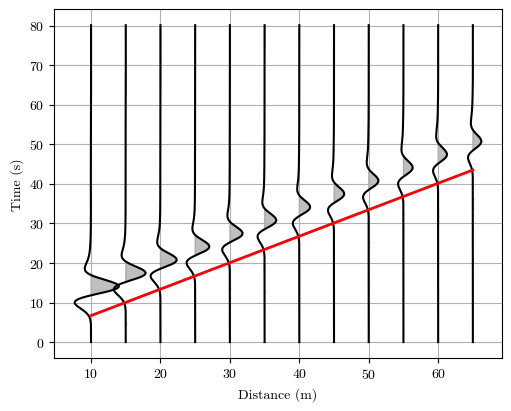

In [4]:
plt.figure(figsize=(5, 4))

scale = 4  # horizontal scaling of wiggles

for i, xpos in enumerate(receiver_positions):
    trace = data[:, i]
    plt.plot(trace * scale + xpos, time, 'k')  # wiggle line
    plt.fill_betweenx(time, xpos, trace * scale + xpos, 
                      where=trace > 0, color='gray', alpha=0.5)

# Add a line between two points
x1, t1 = 10, 6.7    # <-- first arrival pick
x2, t2 = 65.0, 43.5 # <-- second arrival pick

# Slope and apparent velocity
m = (t2 - t1) / (x2 - x1)
v = (x2 - x1) / (t2 - t1)

print(f"slope = {m:.4f} s/m")
print(f"estimated medium velocity = {v:.2f} m/s")
print(f"ground truth medium velocity = 1.50 m/s")


plt.plot([x1, x2], [t1, t2], 'r-', linewidth=2, label="Defined line")

plt.gca()#.invert_yaxis()  # optional: seismic convention: time increases downward
plt.xlabel("Distance (m)", fontsize=10)
plt.ylabel("Time (s)", fontsize=10)

plt.grid(True)
plt.show()

## A single subsurface interface

 ![Wavefield Anination Single Interface](refraction_data/single_interface.gif)


This example shows the travel-time curves of direct and refracted waves recorded at different distances from a seismic source. The velocity of the first layer is related to the slope by:

$$
v_1 = \frac{1}{m_d}
$$

where $m_d$ is the slope of the direct-wave line. Similarly, the travel-time of the refracted wave is given by:

$$
v_2 = \frac{1}{m_r}
$$

where $m_r$ is the slope of the refracted-wave line. Finally, the depth to the refractor can be estimated from

$$
\text{depth} = \tfrac{1}{2} \, X_{cross} \, \sqrt{\frac{v_2 - v_1}{v_2 + v_1}}
$$

The parameter $X_{\text{cross}}$ denotes the *crossover distance*, that is, the source–receiver offset at which the travel times of the direct and refracted waves are equal. Physically, it corresponds to the distance beyond which the refracted wave becomes the first arrival.

### Summary of steps for seismic refraction analysis

- **Step 1:** Find the slope of the direct wave.  
- **Step 2:** Find the slope of the head wave.  
- **Step 3:** Find the crossover distance.  
- **Step 4:** Compute the depth to the boundary.  

### Example

Seismic arrival times were measured using a source and geophones spaced every 3 m up to 69 m to study wave propagation in a single layer model. Direct waves traveled at 1400 m/s, while refracted waves appeared beyond the critical distance at 4500 m/s. Their crossover point indicated a refractor depth of about 10 m, revealing the subsurface velocity structure.

Direct wave slope = 0.7143 ms/m, estimated velocity = 1399.99 m/s, ground truth = 1400 m/s
Refracted wave slope = 0.2222 ms/m, estimated velocity = 4500.16 m/s, ground truth = 4500 m/s
Crossover distance = 27.59 m
Depth to refractor = 10.00 m, ground truth = 10.00 m


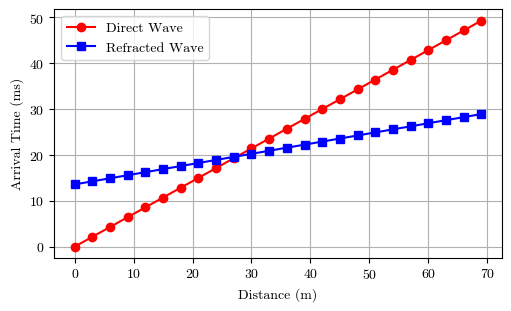

In [5]:
# Load data
arr = np.load("refraction_data/single-layer.npy")

# Split columns
distance = arr[:, 0]     # Source-receiver distance (m)
direct = arr[:, 1]       # Direct wave arrival times (ms)
refracted = arr[:, 2]    # Refracted wave arrival times (ms)

# Linear regression (fit a line) for each wave
coef_direct = np.polyfit(distance, direct, 1)      # slope, intercept
coef_refracted = np.polyfit(distance, refracted, 1)

m_direct, b_direct = coef_direct
m_refracted, b_refracted = coef_refracted

# Velocities (convert slope from ms/m to m/s)
v_direct = 1 / m_direct * 1000
v_refracted = 1 / m_refracted * 1000

print(f"Direct wave slope = {m_direct:.4f} ms/m, estimated velocity = {v_direct:.2f} m/s, ground truth = 1400 m/s")
print(f"Refracted wave slope = {m_refracted:.4f} ms/m, estimated velocity = {v_refracted:.2f} m/s, ground truth = 4500 m/s")

# Assign velocities
v1 = v_direct       # velocity of the first layer
v2 = v_refracted    # velocity of the second layer

# Crossover distance (Xcross)
# Solve m1*x + b1 = m2*x + b2
X_cross = (b_refracted - b_direct) / (m_direct - m_refracted)

# Depth calculation (from crossover method)
depth = 0.5 * np.sqrt((v2 - v1) / (v2 + v1)) * X_cross

print(f"Crossover distance = {X_cross:.2f} m")
print(f"Depth to refractor = {depth:.2f} m, ground truth = 10.00 m")

# Plot arrival times
plt.figure(figsize=(5, 3))
plt.plot(distance, direct, 'o-r', label="Direct Wave")
plt.plot(distance, refracted, 's-b', label="Refracted Wave")

plt.xlabel("Distance (m)")
plt.ylabel("Arrival Time (ms)")
plt.legend()
plt.grid(True)
plt.show()

## Load seismogram data using obspy

In this section, we use **ObsPy** to read seismic data stored in SEG2 format and extract key metadata (e.g., timing, sampling parameters, number of samples, duration, maximum amplitude, and instrument type). The `summarize_seg2()` function iterates through the SEG2 stream and writes a structured summary of the trace headers to a CSV file for easier inspection and documentation.

In [6]:
 # Load the SEG2 file
st = obspy.read("refraction_data/2025-08-13_11-24.seg2", format="seg2")

def summarize_seg2(st, output_csv="refraction_data/seg2_summary.csv"):
    """
    Extract key information from a SEG2 Stream and save it to a CSV file.
    
    Parameters:
        st (obspy.Stream): The SEG2 stream object.
        output_csv (str): Output CSV file path.
    """
    summary = []

    # General instrument info
    instrument = st[0].stats.seg2.get("INSTRUMENT", "Unknown")
    print("=== SEG2 Stream Summary ===")

    for i, tr in enumerate(st):
        stats = tr.stats

        trace_info = {
            "Trace Number": i + 1,
            "Start Time": str(stats.starttime),
            "End Time": str(stats.endtime),
            "Sampling Interval (s)": stats.delta,
            "Sampling Rate (Hz)": stats.sampling_rate,
            "Number of Samples": stats.npts,
            "Duration (s)": round(stats.npts / stats.sampling_rate, 4),
            "Max Amplitude": round(np.max(np.abs(tr.data)), 4),
            "Instrument": instrument
        }

        summary.append(trace_info)

    # Save to CSV
    df = pd.DataFrame(summary)
    df.to_csv(output_csv, index=False)
    return df

df = summarize_seg2(st)
df 

=== SEG2 Stream Summary ===


/home/orincon/miniconda3/envs/seismic-refraction/lib/python3.13/site-packages/obspy/io/seg2/seg2.py:365: UserWarning: Many companies use custom defined SEG2 header variables. This might cause basic header information reflected in the single traces' stats to be wrong (e.g. recording delays, first sample number, station code names, ..). Please check the complete list of additional unmapped header fields that gets stored in Trace.stats.seg2 and/or the manual of the source of the SEG2 files for fields that might influence e.g. trace start times.
  warnings.warn(WARNING_HEADER)


,Trace Number,Start Time,End Time,Sampling Interval (s),Sampling Rate (Hz),Number of Samples,Duration (s),Max Amplitude,Instrument
0,1,2025-08-13T11:24:51.000000Z,2025-08-13T11:24:51.099969Z,0.000031,32000.0,3200,0.1,0.0186,PASI_Gea24
1,2,2025-08-13T11:24:51.000000Z,2025-08-13T11:24:51.099969Z,0.000031,32000.0,3200,0.1,0.0139,PASI_Gea24
2,3,2025-08-13T11:24:51.000000Z,2025-08-13T11:24:51.099969Z,0.000031,32000.0,3200,0.1,0.0123,PASI_Gea24
3,4,2025-08-13T11:24:51.000000Z,2025-08-13T11:24:51.099969Z,0.000031,32000.0,3200,0.1,0.0035,PASI_Gea24


## Seismogram visualization

We generate a wiggle plot of the seismic traces to visualize the recorded waveforms across different geophone positions. Each trace is normalized and shifted horizontally, making it easier to compare wave arrivals across the array. Positive amplitudes are filled for better readability. This type of visualization is commonly used in seismic refraction and reflection studies to analyze first arrivals and wave propagation patterns.  

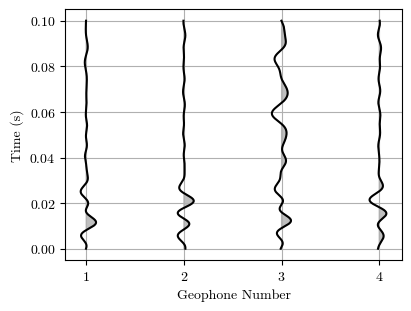

In [7]:
# Sort by station 
st.sort(['station'])

# Time axis
npts = st[0].stats.npts
dt = st[0].stats.delta
time = np.linspace(0, npts * dt, npts)

# Receiver positions = geophone number (index starting from 1)
receiver_positions = np.arange(len(st)) + 1

# Create data matrix: columns = traces
data = np.array([tr.data for tr in st]).T

# Plot wiggle traces
plt.figure(figsize=(4, 3))
scale = 0.1  # horizontal scale factor for wiggle traces

for i, xpos in enumerate(receiver_positions):
    trace = data[:, i]
    trace = trace / np.max(np.abs(trace))  # normalize trace

    plt.plot(trace * scale + xpos, time, 'k')  # wiggle trace
    plt.fill_betweenx(time, xpos, trace * scale + xpos, 
                      where=trace > 0, color='gray', alpha=0.5)

# Axis labels and formatting
plt.xlabel("Geophone Number", fontsize=10)
plt.ylabel("Time (s)", fontsize=10)
plt.xticks(receiver_positions)
plt.grid(True)
 
plt.show()

In [142]:
st

12 Trace(s) in Stream:
... | 1970-01-01T00:00:00.000000Z - 1970-01-01T00:00:00.099938Z | 16000.0 Hz, 1600 samples
... | 1970-01-01T00:00:00.000000Z - 1970-01-01T00:00:00.099938Z | 16000.0 Hz, 1600 samples
... | 1970-01-01T00:00:00.000000Z - 1970-01-01T00:00:00.099938Z | 16000.0 Hz, 1600 samples
... | 1970-01-01T00:00:00.000000Z - 1970-01-01T00:00:00.099938Z | 16000.0 Hz, 1600 samples
... | 1970-01-01T00:00:00.000000Z - 1970-01-01T00:00:00.099938Z | 16000.0 Hz, 1600 samples
... | 1970-01-01T00:00:00.000000Z - 1970-01-01T00:00:00.099938Z | 16000.0 Hz, 1600 samples
... | 1970-01-01T00:00:00.000000Z - 1970-01-01T00:00:00.099938Z | 16000.0 Hz, 1600 samples
... | 1970-01-01T00:00:00.000000Z - 1970-01-01T00:00:00.099938Z | 16000.0 Hz, 1600 samples
... | 1970-01-01T00:00:00.000000Z - 1970-01-01T00:00:00.099938Z | 16000.0 Hz, 1600 samples
... | 1970-01-01T00:00:00.000000Z - 1970-01-01T00:00:00.099938Z | 16000.0 Hz, 1600 samples
... | 1970-01-01T00:00:00.000000Z - 1970-01-01T00:00:00.099938Z | 1

/home/orincon/miniconda3/envs/seismic-refraction/lib/python3.13/site-packages/obspy/io/seg2/seg2.py:365: UserWarning: Many companies use custom defined SEG2 header variables. This might cause basic header information reflected in the single traces' stats to be wrong (e.g. recording delays, first sample number, station code names, ..). Please check the complete list of additional unmapped header fields that gets stored in Trace.stats.seg2 and/or the manual of the source of the SEG2 files for fields that might influence e.g. trace start times.
  warnings.warn(WARNING_HEADER)
/tmp/ipykernel_3538/762242613.py:67: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


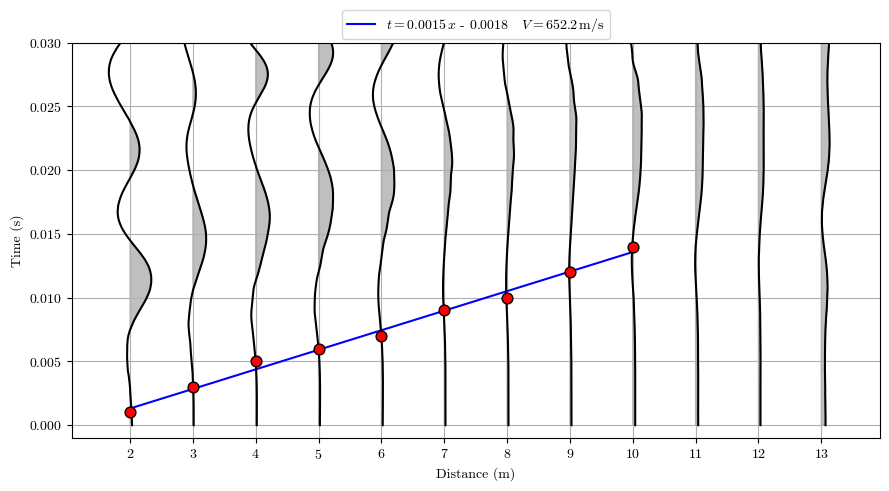

In [153]:
st = obspy.read("refraction_data/Test2_DSAJ_Ing_Civ.seg2", format="seg2")

# Time axis
npts = st[0].stats.npts
dt = st[0].stats.delta
time = np.linspace(0, npts * dt, npts)

# Receiver positions = distance in meters (1 m spacing)
receiver_positions = np.arange(len(st)) + 2  # 1, 2, 3, ...
distances = receiver_positions * 1.0  # meters

# Create data matrix: columns = traces
data = np.array([tr.data for tr in st]).T

# Tiempos de primer arribo (solo para algunos geófonos)
first_arrivals = [0.001, 0.003, 0.005, 0.006, 0.007, 0.009, 0.010, 0.012, 0.014]

# --- Ajuste de recta ---
x_fit = distances[:len(first_arrivals)]  # distancia en metros
y_fit = np.array(first_arrivals)

# polyfit grado 1 => y = m*x + b
m, b = np.polyfit(x_fit, y_fit, 1)

# Velocidad aparente
v_aparente = 1.0 / m  # en m/s

# Generar la línea de ajuste
x_line = np.linspace(min(x_fit), max(x_fit), 100)
y_line = m * x_line + b

# Plot wiggle traces
plt.figure(figsize=(9, 5))
scale = 0.35  # horizontal scale factor for wiggle traces



# Dibujar la recta de ajuste con LaTeX en la leyenda
plt.plot(
    x_line, y_line, color='blue', linewidth=1.5,
    label=fr"$t  =  {m:.4f}\,x $" fr" - {np.abs(b):.4f}   " + fr"$V = {v_aparente:.1f}\,\text{{m/s}}$"
)

for i, xpos in enumerate(receiver_positions):
    trace = data[:, i]
    trace = trace / np.max(np.abs(trace))  # normalize trace

    plt.plot(trace * scale + xpos, time, 'k')  # wiggle trace
    plt.fill_betweenx(time, xpos, trace * scale + xpos, 
                      where=trace > 0, color='gray', alpha=0.5)

    # Marcar primeros arribos como círculos
    if i < len(first_arrivals):
        plt.scatter(xpos, first_arrivals[i], 
                    color='red', edgecolors='black', zorder=5, s=60, marker='o')

# Axis labels and formatting
plt.xlabel("Distance (m)", fontsize=10)
plt.ylabel("Time (s)", fontsize=10)
plt.xticks(receiver_positions)
plt.ylim(-0.001, 0.03)

# Leyenda fuera del recuadro (a la derecha)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, 1.10), ncol=2)

plt.grid(True)
plt.tight_layout()
plt.savefig("refraction_data/cancha_futbol_analisis_refractivo.pdf", dpi=300)
plt.show()